# Example Notebook CHIME Performance SUP

In [1]:
#Importing general libraries
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import fields

In [2]:
#Importing specific chime functions
from chime_perf.params import ChimeParams
from chime_perf.radiometric import snr, nedl, ara
from chime_perf.spatial import psf_kernel



In [3]:
# We load in an instance the Instrument configuration. This is the SNR and ARA
inst = ChimeParams.load()                       # 250 channels, 404.2-2495.8 nm

In [4]:
# We inspect the instance containing all instrument information
fields(ChimeParams.load())
[f.name for f in fields(ChimeParams.load())]

['wavelength_nm',
 'lref',
 'snr_g',
 'snr_n0',
 'ara_a',
 'ara_b',
 'rxra_sigma',
 'default_rxra_sigma',
 'ara_k',
 'ara_s0',
 'mtf_act',
 'mtf_alt',
 'isrf_fwhm_nm',
 'version']

## SNR model

In [5]:
wl=inst.wavelength_nm
#snr function inputs (TOA radiance , Lref, g, n0) 
S_Lref = snr(inst.lref, inst.lref, inst.snr_g, inst.snr_n0)  
S_Lref_05= snr(inst.lref/2, inst.lref, inst.snr_g, inst.snr_n0)
S_Lref_01= snr(inst.lref/10, inst.lref, inst.snr_g, inst.snr_n0)



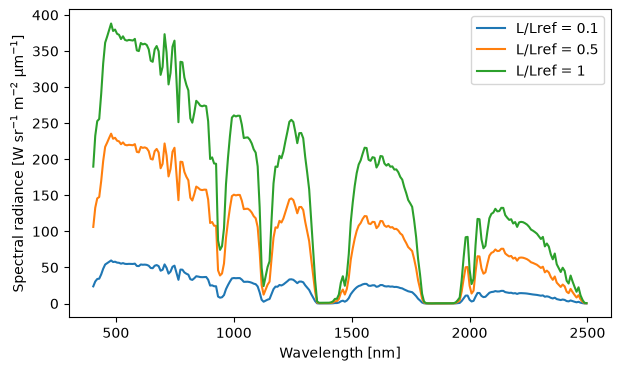

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(wl, S_Lref_01, label="L/Lref = 0.1")
ax.plot(wl, S_Lref_05, label="L/Lref = 0.5")
ax.plot(wl, S_Lref,    label="L/Lref = 1")
ax.set_xlabel("Wavelength [nm]")
ax.set_ylabel(r"Spectral radiance [W sr$^{-1}$ m$^{-2}$ µm$^{-1}$]")
ax.legend()

## ARA Model

In [ ]:
ARA_error_Lref_02 = ara(inst.lref/5, inst.lref, inst.ara_a, inst.ara_b, inst.ara_k, inst.ara_s0)
ARA_error_Lref_05 = ara(inst.lref/2, inst.lref, inst.ara_a, inst.ara_b, inst.ara_k, inst.ara_s0)
ARA_error_Lref = ara(inst.lref, inst.lref, inst.ara_a, inst.ara_b, inst.ara_k, inst.ara_s0)

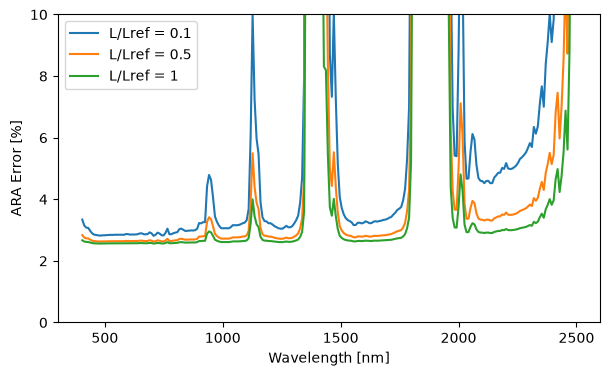

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(wl,ARA_error_Lref_01*100, label="L/Lref = 0.1")
ax.plot(wl,ARA_error_Lref_05*100, label="L/Lref = 0.5")
ax.plot(wl,ARA_error_Lref*100,    label="L/Lref = 1")
ax.set_xlabel("Wavelength [nm]")
ax.set_ylabel(r"ARA Error [%]")
ax.set_ylim(0,10)
ax.legend()

In [9]:
RXRA=inst.rxra_sigma

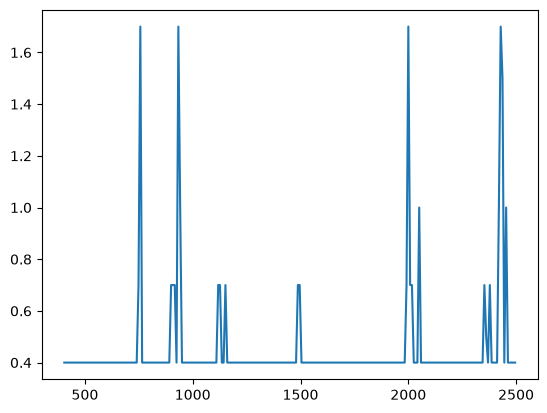

In [11]:
plt.plot(wl,RXRA*100)